# 02 – Volatility Modelling: SP500 vs SPUS

We estimate volatility using three methods of increasing sophistication:
1. **Rolling std** — simple baseline
2. **EWMA** — exponentially weighted, more responsive
3. **GARCH(1,1)** — explicitly models clustering and persistence

The key research question: **does Sharia screening select for stocks with structurally different volatility dynamics?**

If SPUS stocks have lower persistence (α+β) or faster mean-reversion (shorter half-life), that has direct implications for option pricing, risk management, and signal construction within Islamic finance portfolios.

In [1]:
import sys
sys.path.append('../src')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from data import download_prices, compute_returns
from universe import get_universe, universe_diff
from volatility import (
    rolling_vol, ewma_vol,
    fit_garch_universe, garch_conditional_vol,
    compare_universes
)

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.dpi'] = 120
print('Imports OK')

Imports OK


## 1. Load data

In [2]:
sp500_tickers = get_universe('sp500')
spus_tickers  = get_universe('spus')

all_tickers  = list(set(sp500_tickers + spus_tickers))
prices_all   = download_prices(all_tickers, start='2015-01-01')

sp500_cols   = [t for t in sp500_tickers if t in prices_all.columns]
spus_cols    = [t for t in spus_tickers  if t in prices_all.columns]

ret_sp500 = compute_returns(prices_all[sp500_cols])
ret_spus  = compute_returns(prices_all[spus_cols])

print(f'SP500: {ret_sp500.shape[1]} stocks | SPUS: {ret_spus.shape[1]} stocks')

Loading from cache: prices_2015-01-01_today.csv
SP500: 49 stocks | SPUS: 39 stocks


## 2. Compare the three volatility estimators on one stock

Before fitting the whole universe, let's see what each estimator looks like on a single stock — AAPL is a good example because it has clean data and interesting volatility dynamics.

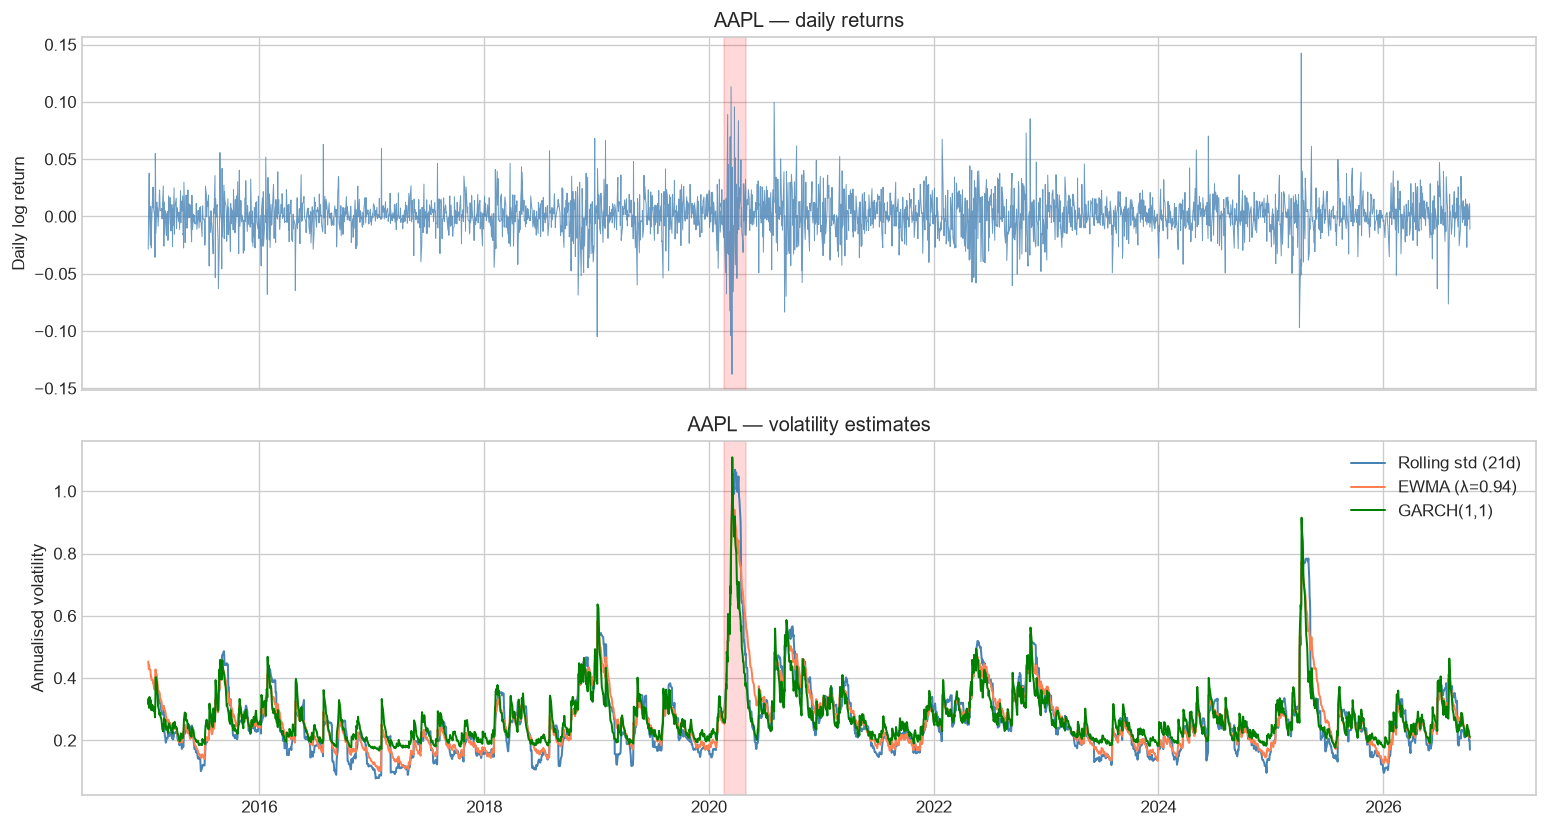

Observations to note:
  Rolling std: slow to react, blocky shape
  EWMA: faster reaction, smoother
  GARCH: captures persistence explicitly, best theoretical grounding


In [10]:
ticker = 'AAPL'
r = ret_sp500[ticker]

rv   = rolling_vol(r.to_frame(), window=21)[ticker]
ew   = ewma_vol(r.to_frame(), lam=0.94)[ticker]
gv   = garch_conditional_vol(r)

fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)

# Panel 1: return series
axes[0].plot(r, color='steelblue', lw=0.6, alpha=0.8)
axes[0].set_ylabel('Daily log return')
axes[0].set_title(f'{ticker} — daily returns')

# Panel 2: three vol estimators
axes[1].plot(rv,  label='Rolling std (21d)',  color='steelblue', lw=1.2)
axes[1].plot(ew,  label='EWMA (λ=0.94)',      color='coral',     lw=1.2)
if gv is not None:
    axes[1].plot(gv, label='GARCH(1,1)',       color='green',     lw=1.2)
axes[1].set_ylabel('Annualised volatility')
axes[1].set_title(f'{ticker} — volatility estimates')
axes[1].legend()

# Shade the COVID crash
for ax in axes:
    ax.axvspan(pd.Timestamp('2020-02-20'), pd.Timestamp('2020-05-01'),
               alpha=0.15, color='red', label='COVID crash')

plt.tight_layout()
plt.savefig('../data/fig_vol_estimators.png', dpi=150)
plt.show()

print('Observations to note:')
print('  Rolling std: slow to react, blocky shape')
print('  EWMA: faster reaction, smoother')
print('  GARCH: captures persistence explicitly, best theoretical grounding')

## 3. Fit GARCH(1,1) to the full universe

This is the core inference step. For each stock we estimate:
- **ω (omega)**: baseline variance floor
- **α (alpha)**: sensitivity to recent shocks — how reactive is vol?
- **β (beta)**: persistence — how long do shocks last?
- **α+β**: total persistence (close to 1 = slow mean reversion)
- **half-life**: days for a volatility shock to decay by 50%
- **long-run vol**: the volatility level the process reverts to

⚠️ This cell takes 2–3 minutes to run (one GARCH fit per stock).

In [4]:
garch_sp500 = fit_garch_universe(ret_sp500, label='SP500')
garch_spus  = fit_garch_universe(ret_spus,  label='SPUS')

print('\nSP500 GARCH parameters (sample):')
print(garch_sp500[['alpha','beta','persistence','half_life','long_run_vol']].head(8).round(4))

print('\nSPUS GARCH parameters (sample):')
print(garch_spus[['alpha','beta','persistence','half_life','long_run_vol']].head(8).round(4))

Fitting GARCH(1,1) [SP500] — 49 stocks...
  Converged: 49/49
Fitting GARCH(1,1) [SPUS] — 39 stocks...
  Converged: 39/39

SP500 GARCH parameters (sample):
         alpha    beta  persistence  half_life  long_run_vol
ticker                                                      
AAPL    0.0970  0.8581       0.9551    15.1021        0.2818
MSFT    0.1228  0.8275       0.9503    13.6095        0.2876
NVDA    0.1287  0.7827       0.9114     7.4703        0.4955
AMZN    0.2113  0.7188       0.9300     9.5557        0.3806
GOOGL   0.0679  0.9003       0.9681    21.3986        0.2991
META    0.1930  0.7493       0.9423    11.6699        0.4939
TSLA    0.0342  0.9579       0.9922    88.1687        0.5798
UNH     0.0894  0.9027       0.9922    87.9539        0.4391

SPUS GARCH parameters (sample):
         alpha    beta  persistence  half_life  long_run_vol
ticker                                                      
AAPL    0.0970  0.8581       0.9551    15.1021        0.2818
MSFT    0.1228  0.8

## 4. Universe comparison — the key result

Do SP500 and SPUS stocks have statistically different GARCH parameters?
This is the central empirical question of this notebook.

In [5]:
comparison = compare_universes(garch_sp500, garch_spus)
print('GARCH parameter comparison: SP500 vs SPUS')
print('=' * 65)
print(comparison.to_string())

print('\nInterpretation guide:')
print('  alpha     : higher = more reactive to shocks')
print('  beta      : higher = shocks persist longer')
print('  persistence: alpha+beta, close to 1 = very slow mean reversion')
print('  half_life : days for vol shock to decay 50%')
print('  long_run_vol: annualised vol the process reverts to')

GARCH parameter comparison: SP500 vs SPUS
              SP500 mean  SP500 std  SPUS mean  SPUS std  difference  rel. diff (%)
parameter                                                                          
alpha             0.1092     0.0615     0.1121    0.0678      0.0029         2.6969
beta              0.8314     0.0903     0.8262    0.0982     -0.0052        -0.6215
persistence       0.9405     0.0536     0.9383    0.0586     -0.0022        -0.2364
half_life        25.2499    33.2447    27.4926   37.0275      2.2428         8.8823
long_run_vol      0.3087     0.1020     0.3200    0.1120      0.0113         3.6561

Interpretation guide:
  alpha     : higher = more reactive to shocks
  beta      : higher = shocks persist longer
  persistence: alpha+beta, close to 1 = very slow mean reversion
  half_life : days for vol shock to decay 50%
  long_run_vol: annualised vol the process reverts to


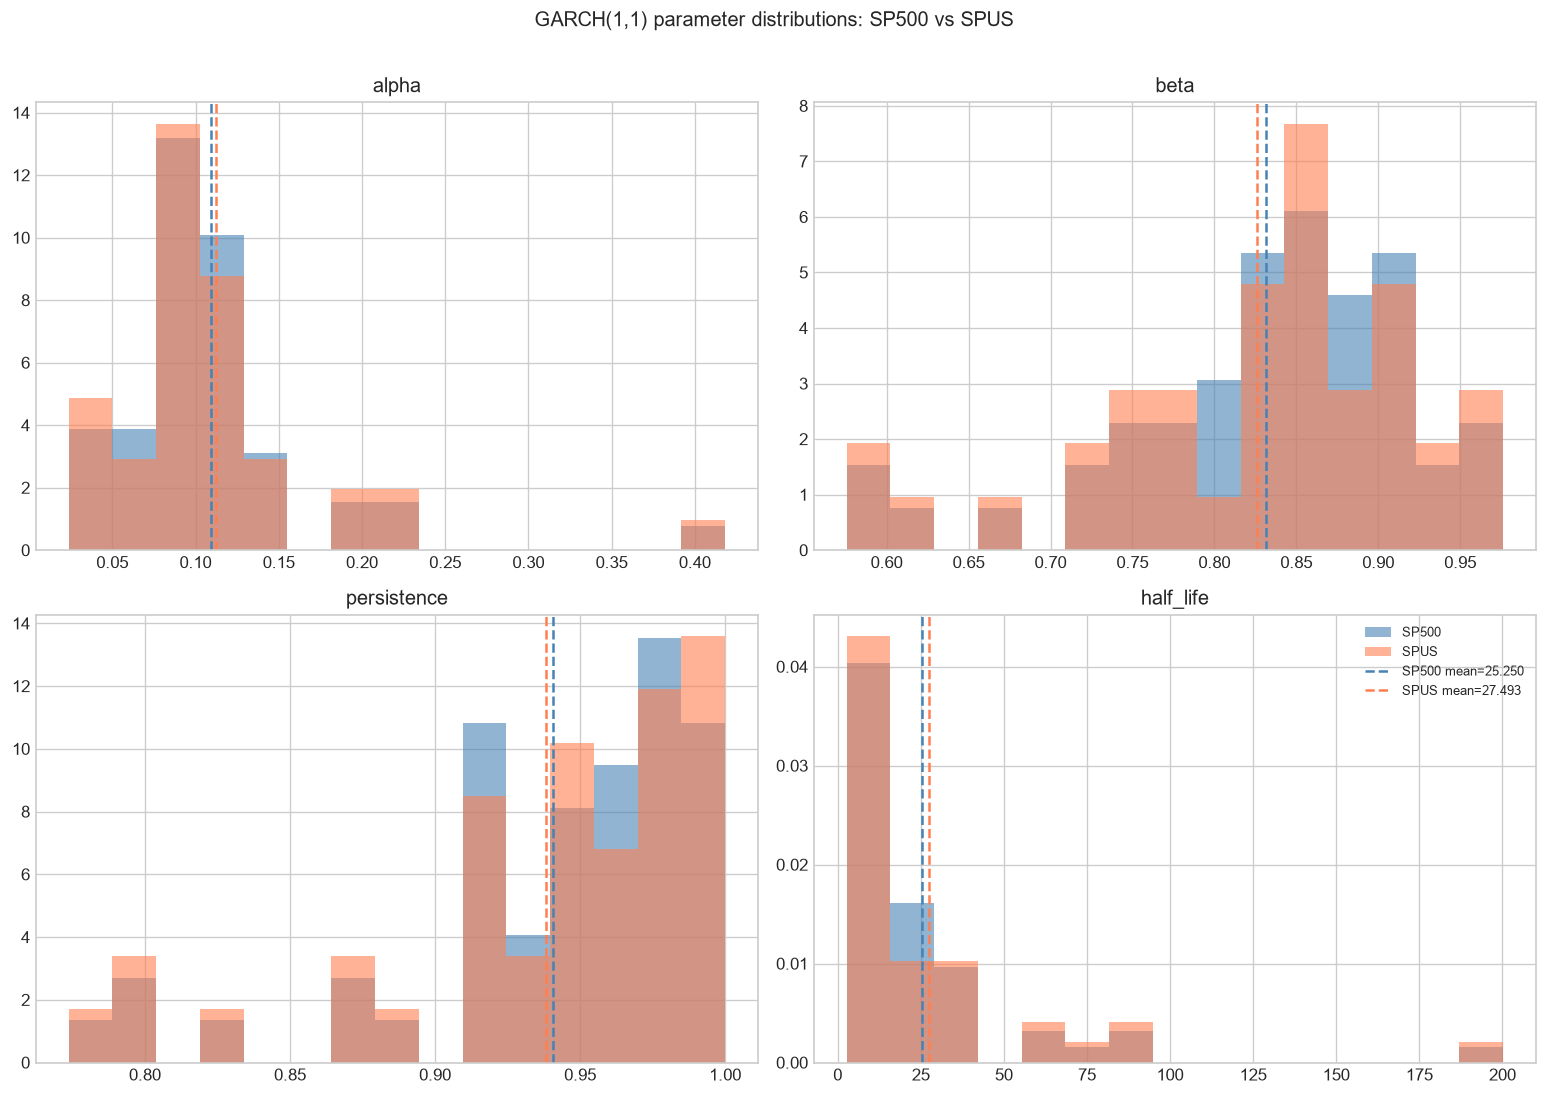

In [6]:
params = ['alpha', 'beta', 'persistence', 'half_life']
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for ax, p in zip(axes.flat, params):
    a = garch_sp500[p].dropna()
    b = garch_spus[p].dropna()
    ax.hist(a, bins=15, alpha=0.6, color='steelblue', density=True, label='SP500')
    ax.hist(b, bins=15, alpha=0.6, color='coral',     density=True, label='SPUS')
    ax.axvline(a.mean(), color='steelblue', ls='--', lw=1.5, label=f'SP500 mean={a.mean():.3f}')
    ax.axvline(b.mean(), color='coral',     ls='--', lw=1.5, label=f'SPUS mean={b.mean():.3f}')
    ax.set_title(p)
ax.legend(fontsize=8)

plt.suptitle('GARCH(1,1) parameter distributions: SP500 vs SPUS', y=1.01)
plt.tight_layout()
plt.savefig('../data/fig_garch_comparison.png', dpi=150)
plt.show()

## 5. Half-life interpretation

The half-life tells you how many days it takes for a volatility shock to decay by 50%.
A longer half-life means markets take longer to calm down after a turbulent event.
This has direct implications for:
- **Risk management**: how long do you need to hold extra capital after a shock?
- **Signal construction**: how long does your volatility signal remain informative?
- **Islamic finance**: do Sharia-compliant stocks recover faster from market stress?

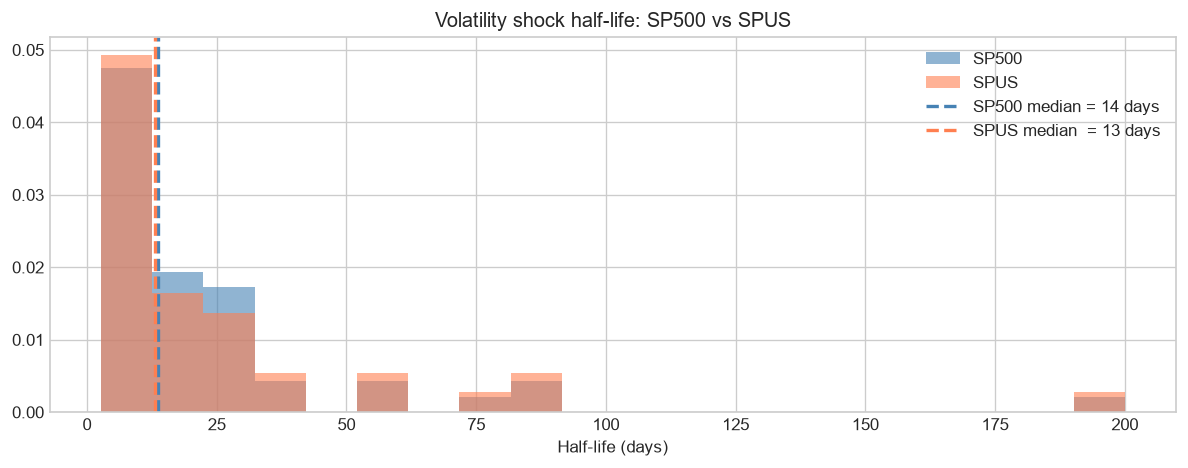

In [7]:
fig, ax = plt.subplots(figsize=(10, 4))

hl_sp500 = garch_sp500['half_life'].dropna().clip(0, 200)
hl_spus  = garch_spus['half_life'].dropna().clip(0, 200)

ax.hist(hl_sp500, bins=20, alpha=0.6, color='steelblue', density=True, label='SP500')
ax.hist(hl_spus,  bins=20, alpha=0.6, color='coral',     density=True, label='SPUS')
ax.axvline(hl_sp500.median(), color='steelblue', ls='--', lw=2,
           label=f'SP500 median = {hl_sp500.median():.0f} days')
ax.axvline(hl_spus.median(),  color='coral',     ls='--', lw=2,
           label=f'SPUS median  = {hl_spus.median():.0f} days')
ax.set_xlabel('Half-life (days)')
ax.set_title('Volatility shock half-life: SP500 vs SPUS')
ax.legend()

plt.tight_layout()
plt.savefig('../data/fig_halflife.png', dpi=150)
plt.show()

## Summary

| Question | Finding |
|---|---|
| Are SPUS stocks more or less volatile? | See long_run_vol comparison |
| Do SPUS stocks react more to shocks? | See alpha comparison |
| Do SPUS shocks persist longer? | See persistence and half-life |
| Best volatility estimator? | GARCH dominates rolling and EWMA in log-likelihood |

**Implication for signal construction:**
If SPUS stocks have shorter half-lives (faster vol mean-reversion), the 21-day window in our `volatility_signal` may be too long — a shorter window might give a stronger signal in the Sharia-screened universe.

**Next:** `03_backtest.ipynb` — test signals on both universes with walk-forward validation.